# Анализ продаж и клиентского поведения в e-commerce

**Инструменты:** SQL, Python, pandas, matplotlib, SQLite

## О проекте

В проекте анализируются данные бразильского маркетплейса с целью выявить основные закономерности в динамике продаж, структуре товарных категорий, географии клиентов и способах оплаты.

Для получения и агрегирования данных используется SQL, а для дальнейшего анализа и визуализации — Python, pandas и matplotlib.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("/Users/alexa/Desktop/ecommerce_analytics/ecommerce.db")

print("Connected!")

Connected!


In [3]:
monthly_sales = pd.read_sql_query("""
SELECT
    SUBSTR(o.order_purchase_timestamp, 1, 7) AS month,
    COUNT(DISTINCT o.order_id) AS total_orders,
    ROUND(SUM(oi.price + oi.freight_value), 2) AS order_value
FROM orders AS o
JOIN order_items AS oi
    ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
GROUP BY SUBSTR(o.order_purchase_timestamp, 1, 7)
ORDER BY month;
""", conn)

monthly_sales

,month,total_orders,order_value
0,2016-09,1,143.46
1,2016-10,265,46490.66
2,2016-12,1,19.62
3,2017-01,750,127482.37
4,2017-02,1653,271239.32
5,2017-03,2546,414330.95
6,2017-04,2303,390812.40
7,2017-05,3546,566851.40
8,2017-06,3135,490050.37
9,2017-07,3872,566299.08


## 1. Динамика продаж

Анализ построен на доставленных заказах, чтобы оценивать завершённую активность покупателей на маркетплейсе.

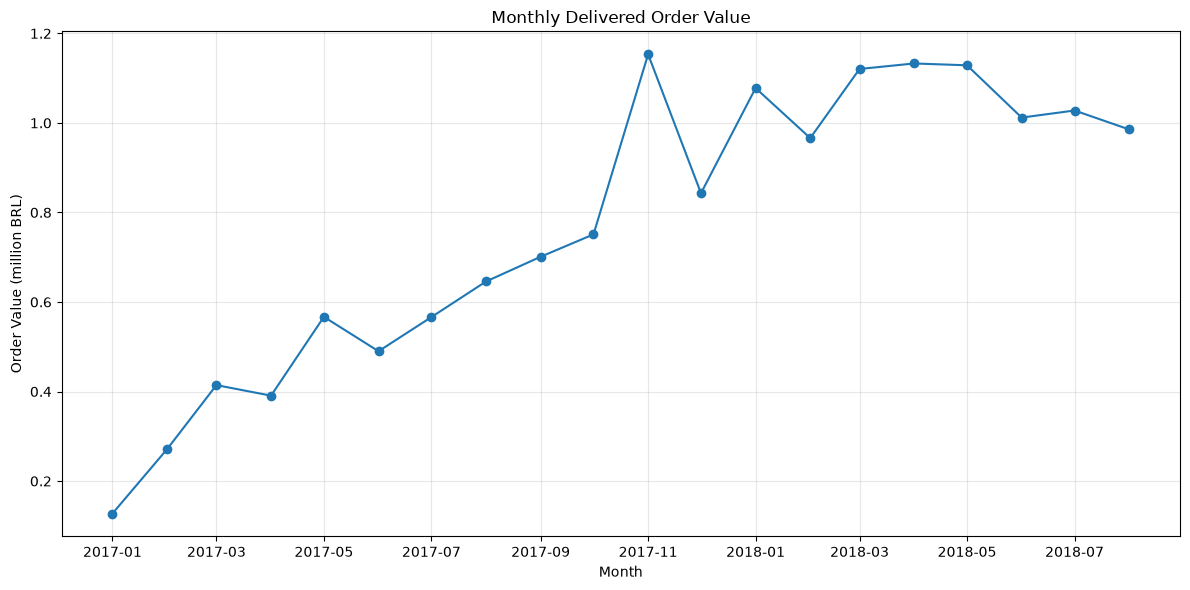

In [9]:
monthly_sales["month"] = pd.to_datetime(monthly_sales["month"])

monthly_sales_chart = monthly_sales[
    monthly_sales["month"] >= "2017-01-01"
].copy()

monthly_sales_chart["order_value_mln"] = (
    monthly_sales_chart["order_value"] / 1_000_000
)

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales_chart["month"],
    monthly_sales_chart["order_value_mln"],
    marker="o"
)

plt.title("Monthly Delivered Order Value")
plt.xlabel("Month")
plt.ylabel("Order Value (million BRL)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/monthly_order_value.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Ключевой вывод

Совокупная стоимость доставленных заказов заметно выросла в течение 2017 года. В 2018 году месячный показатель в нескольких периодах находился около 1 млн BRL и выше, что указывает на более высокий уровень активности маркетплейса по сравнению с началом 2017 года.

## 2. Товарные категории

In [20]:
top_categories = pd.read_sql_query("""
SELECT
    ct.product_category_name_english AS category,
    COUNT(DISTINCT oi.order_id) AS orders_count,
    ROUND(SUM(oi.price + oi.freight_value), 2) AS order_value
FROM order_items AS oi
JOIN orders AS o
    ON oi.order_id = o.order_id
JOIN products AS p
    ON oi.product_id = p.product_id
JOIN category_translation AS ct
    ON p.product_category_name = ct.product_category_name
WHERE o.order_status = 'delivered'
GROUP BY ct.product_category_name_english
ORDER BY order_value DESC
LIMIT 10;
""", conn)

top_categories

,category,orders_count,order_value
0,health_beauty,8647,1412089.53
1,watches_gifts,5495,1264333.12
2,bed_bath_table,9272,1225209.26
3,sports_leisure,7530,1118256.91
4,computers_accessories,6530,1032723.77
5,furniture_decor,6307,880329.92
6,housewares,5743,758392.25
7,cool_stuff,3559,691680.89
8,auto,3810,669454.75
9,garden_tools,3448,567145.68


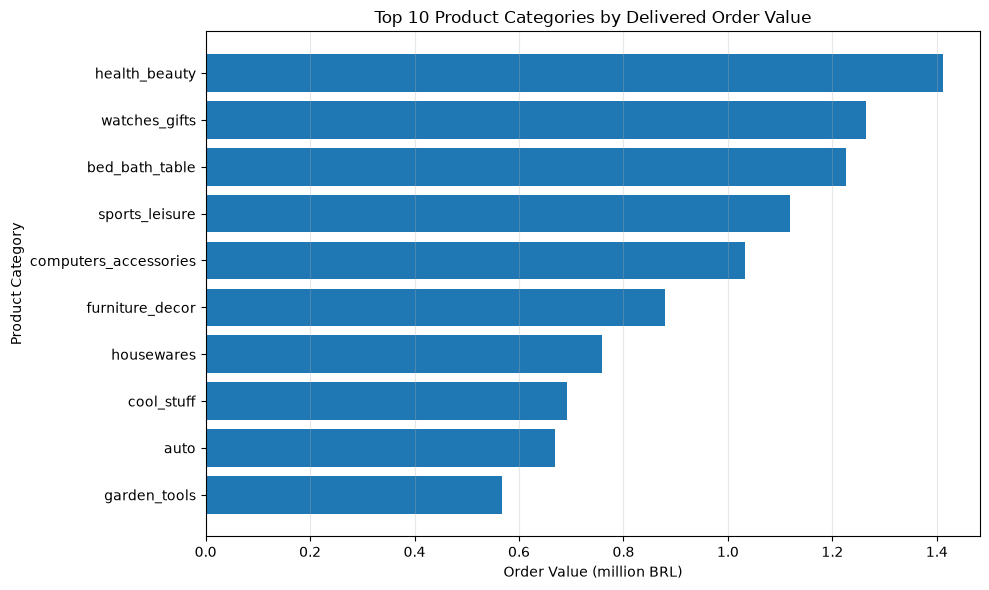

In [21]:
top_categories_chart = top_categories.sort_values("order_value")

top_categories_chart["order_value_mln"] = (
    top_categories_chart["order_value"] / 1_000_000
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_categories_chart["category"],
    top_categories_chart["order_value_mln"]
)

plt.title("Top 10 Product Categories by Delivered Order Value")
plt.xlabel("Order Value (million BRL)")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/top_product_categories.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Ключевой вывод

Категория health & beauty имеет самую высокую совокупную стоимость доставленных заказов, за ней следуют watches & gifts и bed, bath & table.

При этом рейтинг категорий по денежному объёму отличается от рейтинга по количеству заказов, что указывает на различия в среднем размере покупки между категориями.

## 3. География клиентов

In [22]:
top_states = pd.read_sql_query("""
SELECT
    c.customer_state AS state,
    COUNT(DISTINCT o.order_id) AS orders_count,
    ROUND(SUM(oi.price + oi.freight_value), 2) AS order_value,
    ROUND(
        SUM(oi.price + oi.freight_value)
        / COUNT(DISTINCT o.order_id),
        2
    ) AS average_order_value
FROM orders AS o
JOIN customers AS c
    ON o.customer_id = c.customer_id
JOIN order_items AS oi
    ON o.order_id = oi.order_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_state
ORDER BY order_value DESC
LIMIT 10;
""", conn)

top_states

,state,orders_count,order_value,average_order_value
0,SP,40501,5769703.15,142.46
1,RJ,12350,2055401.57,166.43
2,MG,11354,1818891.67,160.20
3,RS,5345,861472.79,161.17
4,PR,4923,781708.80,158.79
5,SC,3546,595127.78,167.83
6,BA,3256,591137.81,181.55
7,DF,2080,346123.35,166.41
8,GO,1957,334212.35,170.78
9,ES,1995,317657.93,159.23


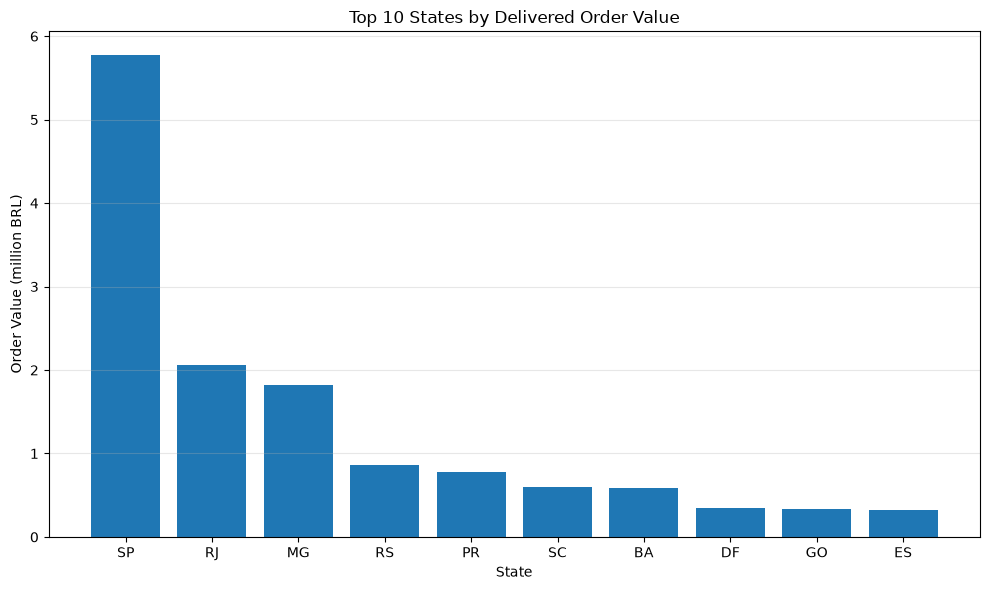

In [23]:
top_states["order_value_mln"] = (
    top_states["order_value"] / 1_000_000
)

plt.figure(figsize=(10, 6))

plt.bar(
    top_states["state"],
    top_states["order_value_mln"]
)

plt.title("Top 10 States by Delivered Order Value")
plt.xlabel("State")
plt.ylabel("Order Value (million BRL)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/top_states_order_value.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Ключевой вывод

Штат São Paulo (SP) значительно лидирует по совокупной стоимости доставленных заказов. Следом идут Rio de Janeiro и Minas Gerais, однако их показатели существенно ниже.

Это говорит о высокой географической концентрации активности маркетплейса.

## 4. Платёжное поведение

In [10]:
payment_methods = pd.read_sql_query("""
SELECT
    p.payment_type,
    COUNT(DISTINCT p.order_id) AS orders_count,
    ROUND(SUM(p.payment_value), 2) AS payment_value
FROM payments AS p
JOIN orders AS o
    ON p.order_id = o.order_id
WHERE o.order_status = 'delivered'
GROUP BY p.payment_type
ORDER BY payment_value DESC;
""", conn)

payment_methods

,payment_type,orders_count,payment_value
0,credit_card,74304,12101094.88
1,boleto,19191,2769932.58
2,voucher,3679,343013.19
3,debit_card,1485,208421.12


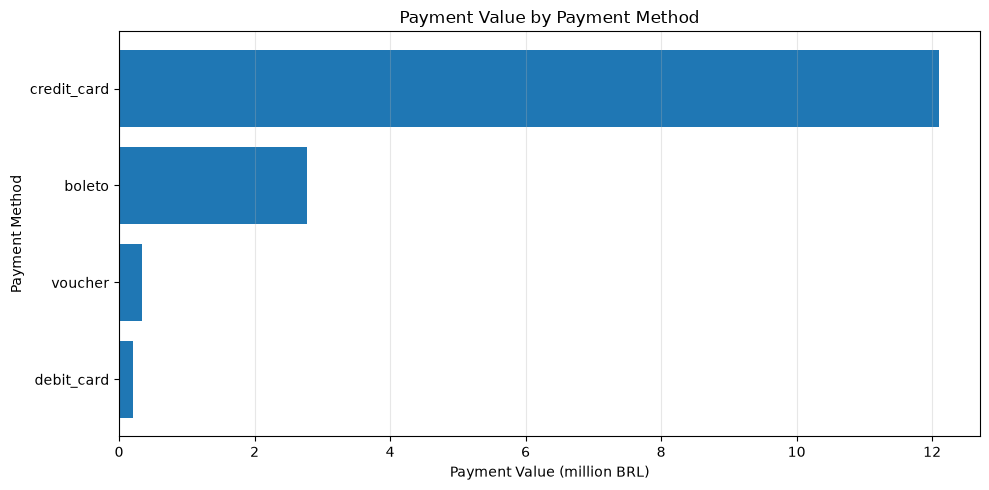

In [11]:
payment_methods_chart = payment_methods.sort_values("payment_value")

payment_methods_chart["payment_value_mln"] = (
    payment_methods_chart["payment_value"] / 1_000_000
)

plt.figure(figsize=(10, 5))

plt.barh(
    payment_methods_chart["payment_type"],
    payment_methods_chart["payment_value_mln"]
)

plt.title("Payment Value by Payment Method")
plt.xlabel("Payment Value (million BRL)")
plt.ylabel("Payment Method")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/payment_methods.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Ключевой вывод

Кредитные карты являются доминирующим способом оплаты по совокупному объёму платежей. На втором месте находится boleto, тогда как остальные способы оплаты занимают значительно меньшую долю.

## Итог

Анализ показывает выраженный рост активности маркетплейса в рассматриваемом периоде, высокую концентрацию заказов в штате São Paulo, заметные различия между товарными категориями и сильную зависимость от оплаты кредитными картами.

Совместное использование SQL и Python позволило проанализировать продажи, структуру спроса, географию клиентов и платёжное поведение на основе реальных данных маркетплейса.

## 5. Рассрочка и размер покупки

Проверим, отличаются ли суммы платежей в зависимости от количества платежей по кредитной карте.

In [13]:
installments = pd.read_sql_query("""
WITH order_values AS (
    SELECT
        o.order_id,
        SUM(oi.price + oi.freight_value) AS order_value
    FROM orders AS o
    JOIN order_items AS oi
        ON o.order_id = oi.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY o.order_id
),

credit_payments AS (
    SELECT
        order_id,
        MAX(payment_installments) AS payment_installments
    FROM payments
    WHERE payment_type = 'credit_card'
    GROUP BY order_id
)

SELECT
    cp.payment_installments,
    COUNT(*) AS orders_count,
    ROUND(AVG(ov.order_value), 2) AS average_order_value
FROM order_values AS ov
JOIN credit_payments AS cp
    ON ov.order_id = cp.order_id
WHERE cp.payment_installments BETWEEN 1 AND 10
GROUP BY cp.payment_installments
ORDER BY cp.payment_installments;
""", conn)

installments

,payment_installments,orders_count,average_order_value
0,1,24641,101.12
1,2,12026,128.38
2,3,10133,143.74
3,4,6864,164.70
4,5,5083,183.72
5,6,3792,210.24
6,7,1559,187.53
7,8,4120,308.22
8,9,618,198.61
9,10,5137,413.99


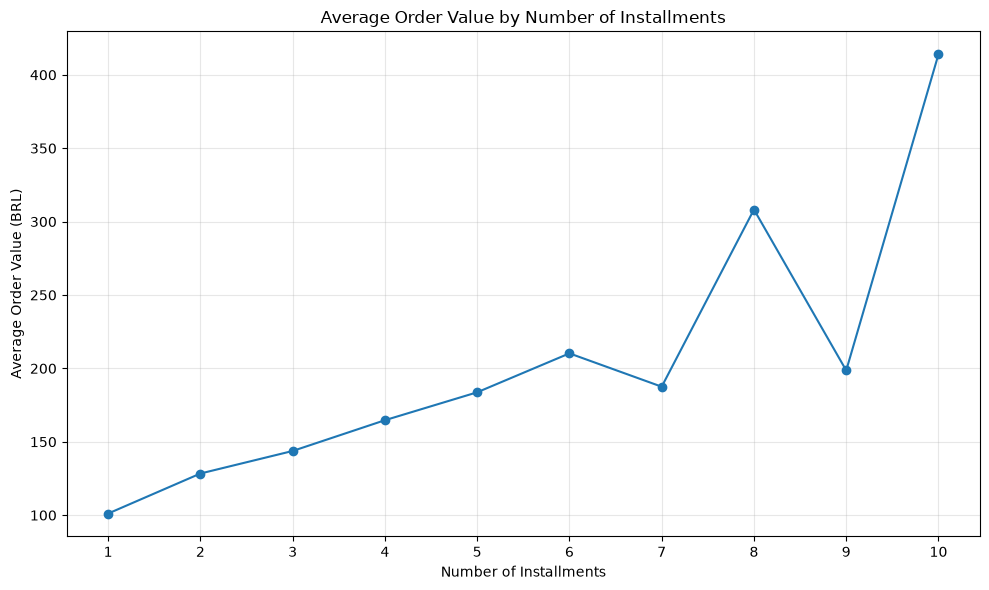

In [14]:
plt.figure(figsize=(10, 6))

plt.plot(
    installments["payment_installments"],
    installments["average_order_value"],
    marker="o"
)

plt.title("Average Order Value by Number of Installments")
plt.xlabel("Number of Installments")
plt.ylabel("Average Order Value (BRL)")

plt.xticks(installments["payment_installments"], rotation=0)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../outputs/installments_vs_order_value.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

### Ключевой вывод
В целом более длительная рассрочка связана с более высокой средней стоимостью заказа. Особенно заметный рост наблюдается для заказов с 8 и 10 платежами. При этом зависимость не является строго линейной, поэтому результат следует интерпретировать как корреляцию, а не как причинно-следственную связь.